# Fig 1 choice CD analysis:

In [2]:

import sys
sys.path.append("C:\scripts\Imaging analysis")
import numpy as np
import scipy.io as scio
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
# import decon
from scipy.stats import chisquare
import pandas as pd
from scipy import stats
from sklearn.metrics.pairwise import cosine_similarity

import sys
sys.path.append("C:\scripts\Ephys analysis\ephys_pipeline")
import numpy as np
import scipy.io as scio
import matplotlib.pyplot as plt
from activitymode import Mode

from ephysSession import Session
import behavior
cat = np.concatenate
plt.rcParams['pdf.fonttype'] = '42' 


In [ ]:
naive_paths = [
                # r'J:\ephys_data\CW48\python\2024_10_29',
                # r'J:\ephys_data\CW48\python\2024_10_30',
                r'J:\ephys_data\CW48\python\2024_10_31',
                r'J:\ephys_data\CW48\python\2024_11_01',
                r'J:\ephys_data\CW48\python\2024_11_02',
                r'J:\ephys_data\CW48\python\2024_11_03',
                r'J:\ephys_data\CW48\python\2024_11_04',
                r'J:\ephys_data\CW48\python\2024_11_05',
                r'J:\ephys_data\CW48\python\2024_11_06',
                ]

trained_paths = [
            [ r'K:\data\CW69\python\2025_12_19',
              ],
            [r'L:\data\CW68\python\2025_12_10',
              r'L:\data\CW68\python\2025_12_12',
              r'L:\data\CW68\python\2025_12_13',
              r'L:\data\CW68\python\2025_12_15',
              ],
            # [r'L:\data\CW70\python\2025_11_04',

            #  ],
            [r'G:\ephys_data\CW65\python\2025_02_25',
              ],
            [r'H:\ephys_data\CW47\python\2024_10_17',
              r'H:\ephys_data\CW47\python\2024_10_22',
              r'H:\ephys_data\CW47\python\2024_10_25',
              ],
            [r'K:\data\CW85\python\2026_02_07',
              r'K:\data\CW85\python\2026_02_10',
             
              ],
            [r'M:\data\CW87\python\2026_02_20',
              r'M:\data\CW87\python\2026_02_21',
              ],
            [r'K:\data\CW84\python\2026_03_11',
             r'K:\data\CW84\python\2026_03_14',
             r'K:\data\CW84\python\2026_03_15',
             r'K:\data\CW84\python\2026_03_16',
             r'K:\data\CW84\python\2026_03_17',
             r'K:\data\CW84\python\2026_03_18',
             r'K:\data\CW84\python\2026_03_19',
             r'K:\data\CW84\python\2026_03_20',
             ],

              [
              r'P:\data\CW92\python\2026_06_17',
              r'P:\data\CW92\python\2026_06_18',
              r'P:\data\CW92\python\2026_06_19',
              r'P:\data\CW92\python\2026_06_21',
              r'P:\data\CW92\python\2026_06_23',
              r'P:\data\CW92\python\2026_06_24',
              r'P:\data\CW92\python\2026_06_25',
              r'P:\data\CW92\python\2026_06_26',
              r'P:\data\CW92\python\2026_06_27',
              r'P:\data\CW92\python\2026_06_28',
              r'P:\data\CW92\python\2026_06_29',
              r'P:\data\CW92\python\2026_06_30',
              r'P:\data\CW92\python\2026_07_01',

             ]

             
            ]



## Naive choice CD:

16 trials removed for stability reasons
only ppyr neurons: 299 --> 147
in house train test sorting
time taken: 22.130892992019653


c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:184: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


calculation time: 0.2141110897064209


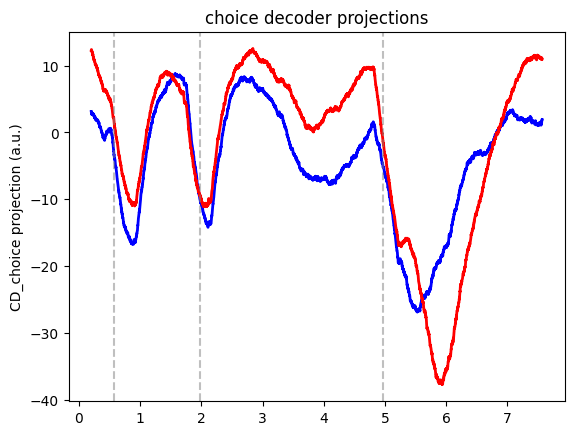

11 trials removed for stability reasons
only ppyr neurons: 225 --> 81
in house train test sorting
time taken: 10.591238021850586
calculation time: 0.06455039978027344


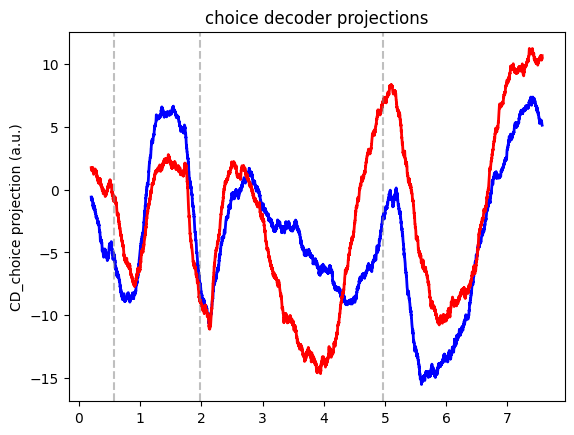

28 trials removed for stability reasons
only ppyr neurons: 270 --> 147
in house train test sorting


In [ ]:
all_norm_right_proj = []
all_norm_left_proj = []
for path in naive_paths:
    s1 = Mode(path, filter_low_perf=False, proportion_train=0.6)#, timestep=1)#, passive=False)
    right_proj, left_proj = s1.plot_CD(mode_input='choice', return_traces=True)

    overall_mean, overall_std = np.mean((right_proj, left_proj)), np.std((right_proj, left_proj))
    right_proj = (right_proj - overall_mean) / overall_std
    left_proj = (left_proj - overall_mean) / overall_std
    all_norm_right_proj.append(right_proj)
    all_norm_left_proj.append(left_proj)



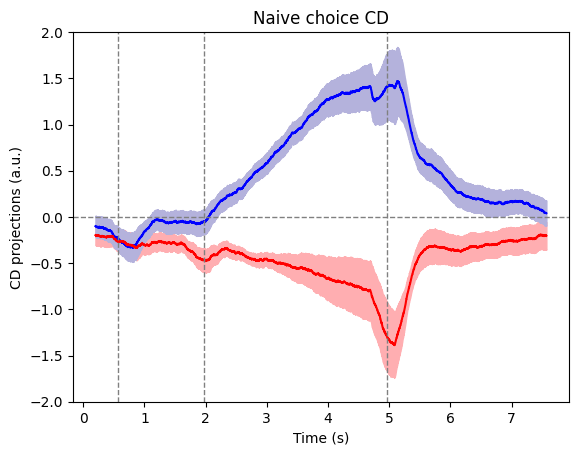

In [ ]:
x=s1.t
all_std_right = np.std(all_norm_right_proj, axis=0)[:,0] / np.sqrt(len(all_norm_right_proj))
all_std_left = np.std(all_norm_left_proj, axis=0)[:,0] / np.sqrt(len(all_norm_left_proj))

f=plt.figure()
plt.plot(x,np.mean(all_norm_right_proj, axis=0)[:,0], 'b')
plt.plot(x,np.mean(all_norm_left_proj, axis=0)[:,0], 'r')

plt.fill_between(x, np.mean(all_norm_left_proj, axis=0)[:,0] - all_std_left, 
        np.mean(all_norm_left_proj, axis=0)[:,0] + all_std_left,
        color=['#ffaeb1'])
plt.fill_between(x, np.mean(all_norm_right_proj, axis=0)[:,0] - all_std_right, 
        np.mean(all_norm_right_proj, axis=0)[:,0] + all_std_right,
        color=['#b4b2dc'])


plt.axhline(0, color='gray', linewidth=1, ls='--')
plt.axvline(s1.sample, color='gray', linewidth=1, ls='--')
plt.axvline(s1.delay, color='gray', linewidth=1, ls='--')
plt.axvline(s1.response, color='gray', linewidth=1, ls='--')
plt.xlabel('Time (s)')
plt.ylabel('CD projections (a.u.)')
plt.title('Naive choice CD')
plt.ylim(-2, 2)
plt.savefig(r'P:\paperfigures\fig1\cd_choice_naive.pdf')
plt.show()

### Trained choice CD:

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 216 --> 175
in house train test sorting
time taken: 15.325831413269043
calculation time: 0.14834022521972656


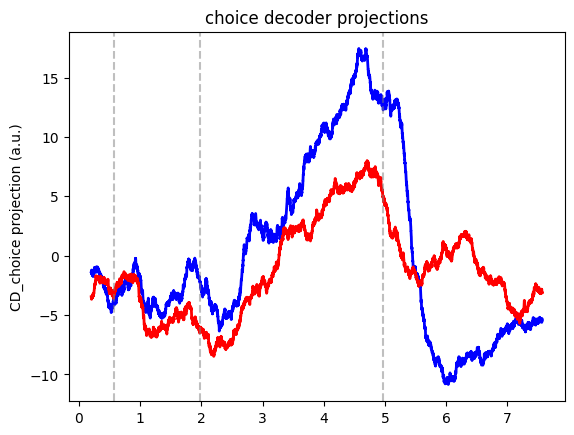

Loading good trial inds from file
7 trials removed for stability reasons
only ppyr neurons: 305 --> 264
in house train test sorting
time taken: 33.902594804763794
calculation time: 0.23646807670593262


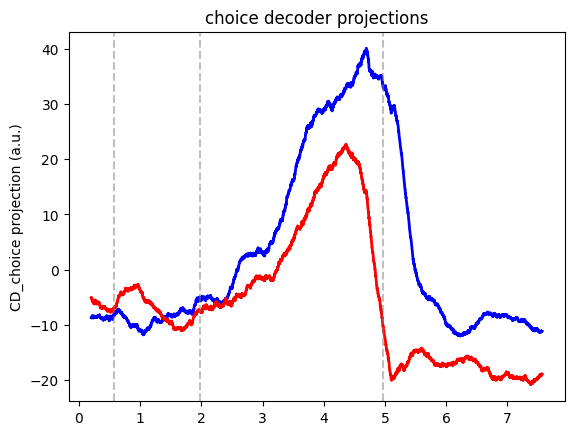

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 422 --> 361
in house train test sorting
time taken: 63.998499393463135
calculation time: 0.33040714263916016


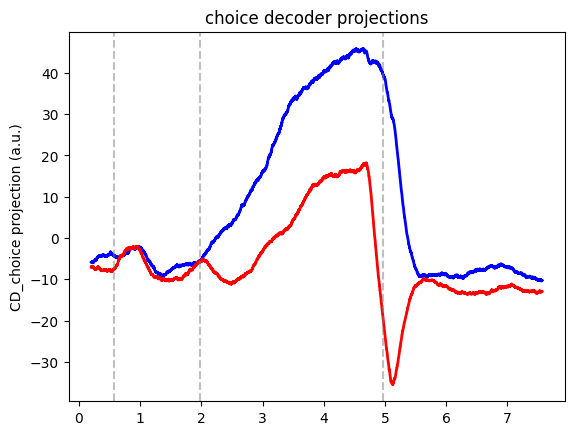

Loading good trial inds from file
20 trials removed for stability reasons
only ppyr neurons: 328 --> 279
in house train test sorting
time taken: 39.33547282218933
calculation time: 0.22784066200256348


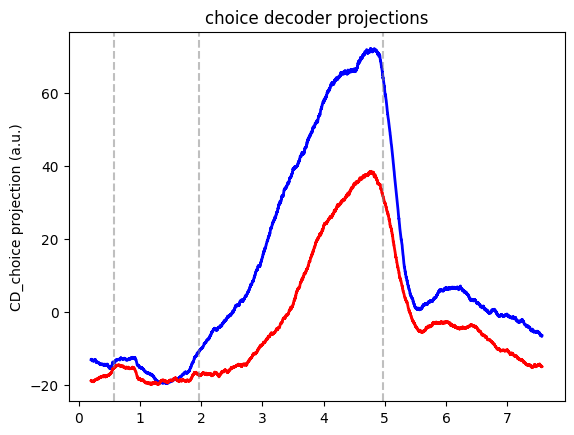

Loading good trial inds from file
15 trials removed for stability reasons
only ppyr neurons: 178 --> 151
in house train test sorting
time taken: 15.74245572090149
calculation time: 0.13002967834472656


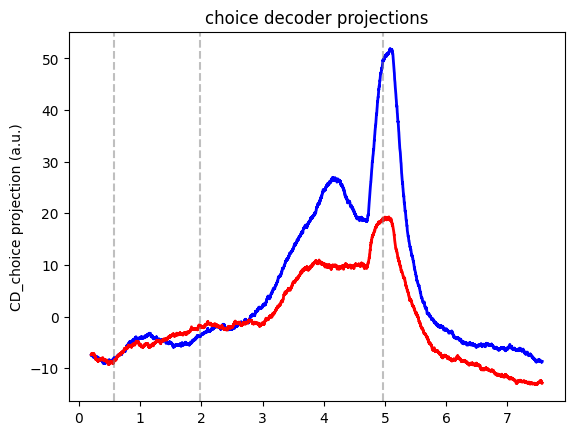

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 407 --> 344
in house train test sorting
time taken: 46.30270528793335
calculation time: 0.4349510669708252


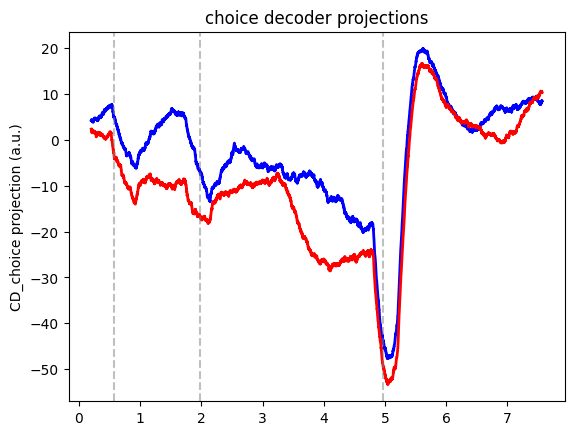

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 271 --> 238
in house train test sorting
time taken: 33.508639097213745
calculation time: 0.17798805236816406


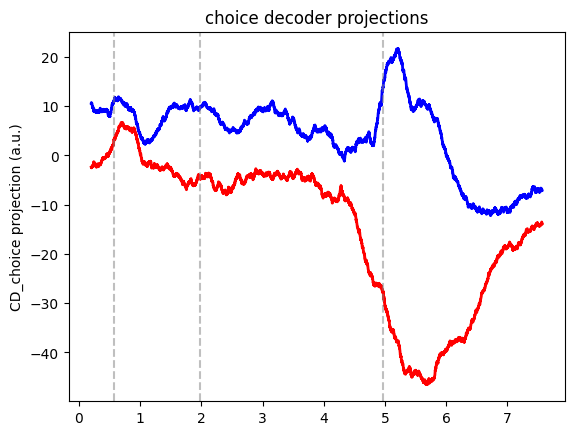

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 344 --> 287
in house train test sorting
time taken: 37.70770812034607
calculation time: 0.25808072090148926


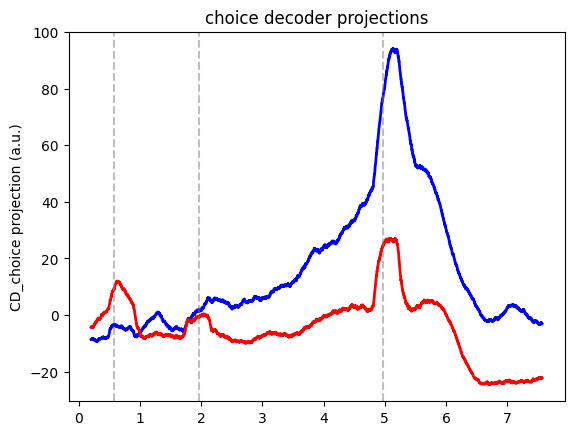

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 349 --> 287
in house train test sorting
time taken: 30.61390495300293
calculation time: 0.32940006256103516


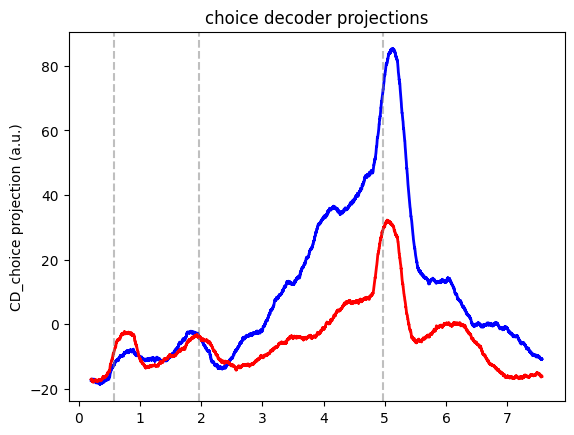

Loading good trial inds from file
4 trials removed for stability reasons
only ppyr neurons: 249 --> 205
in house train test sorting
time taken: 28.561471700668335
calculation time: 0.19325947761535645


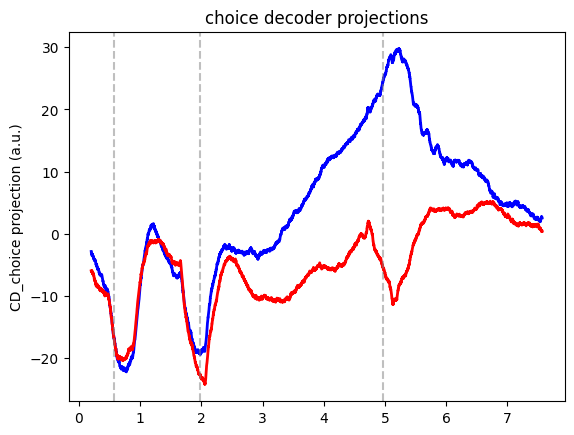

Loading good trial inds from file
14 trials removed for stability reasons
only ppyr neurons: 173 --> 145
in house train test sorting
time taken: 13.505825757980347
calculation time: 0.15168333053588867


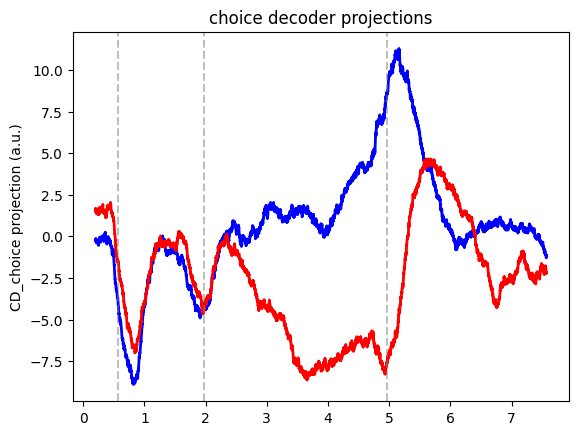

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 343 --> 292
in house train test sorting
time taken: 46.397671937942505
calculation time: 0.36185121536254883


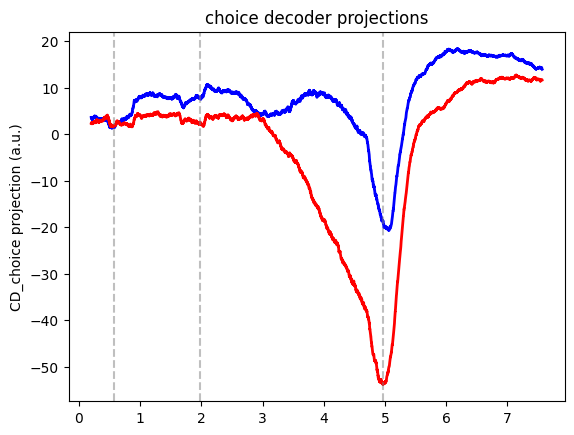

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 516 --> 429
in house train test sorting
time taken: 79.76941251754761
calculation time: 0.3465578556060791


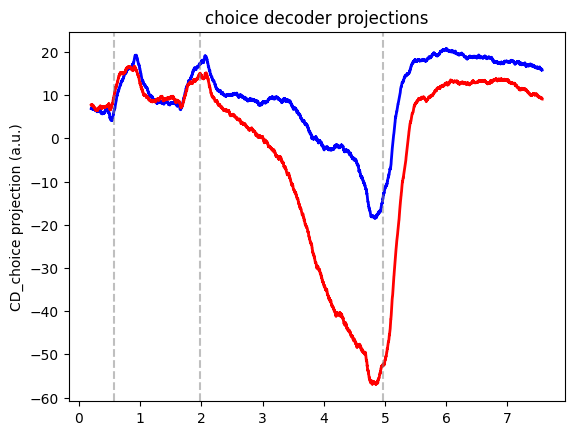

Loading good trial inds from file
15 trials removed for stability reasons
only ppyr neurons: 361 --> 303
in house train test sorting
time taken: 41.161022424697876
calculation time: 0.24732184410095215


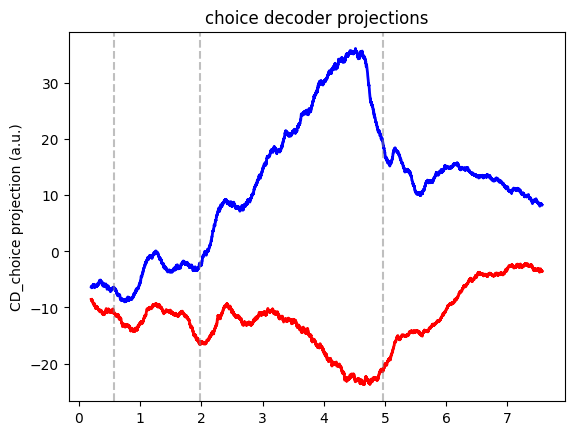

Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 192 --> 145
in house train test sorting
time taken: 11.397022724151611
calculation time: 0.1105051040649414


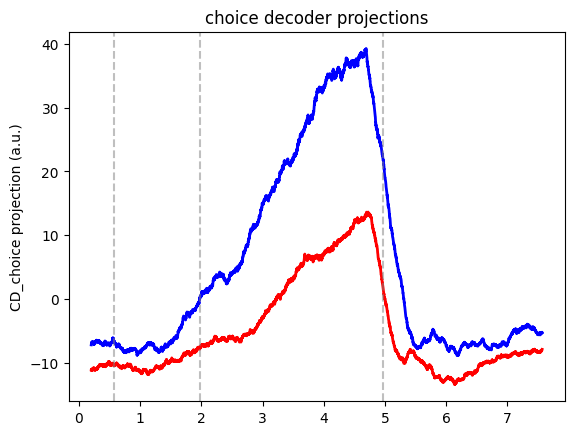

Loading good trial inds from file
28 trials removed for stability reasons
only ppyr neurons: 504 --> 417
in house train test sorting
time taken: 55.89345860481262
calculation time: 0.35676145553588867


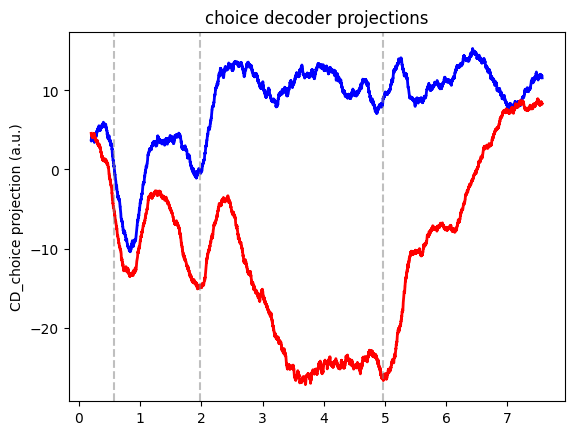

Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 368 --> 302
in house train test sorting
time taken: 44.9549777507782
calculation time: 0.2299950122833252


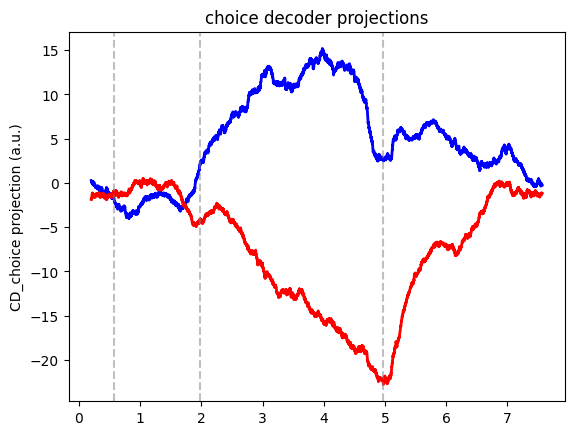

Loading good trial inds from file
32 trials removed for stability reasons
only ppyr neurons: 218 --> 181
in house train test sorting
time taken: 16.240166425704956
calculation time: 0.1628870964050293


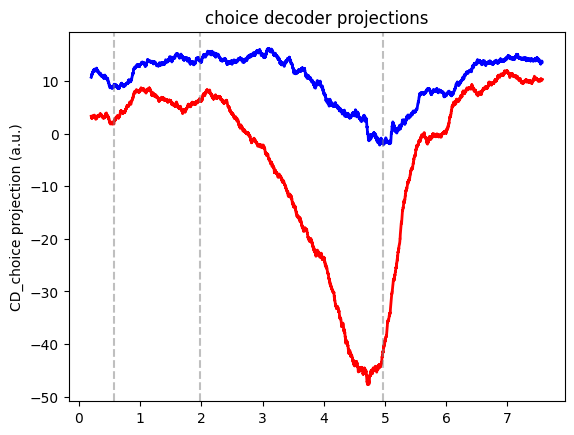

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 203 --> 168
in house train test sorting
time taken: 18.377806425094604
calculation time: 0.16868185997009277


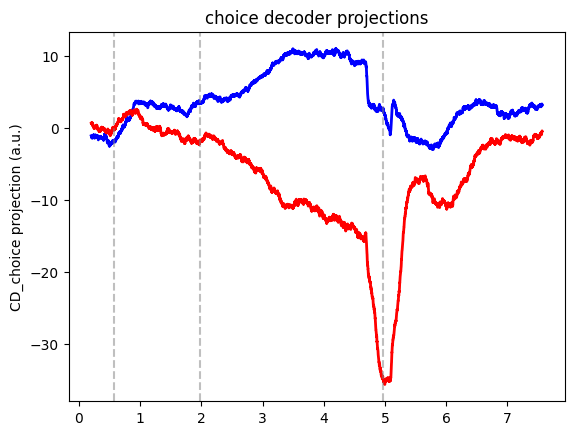

Loading good trial inds from file
6 trials removed for stability reasons
only ppyr neurons: 362 --> 280
in house train test sorting
time taken: 30.267038583755493
calculation time: 0.2660384178161621


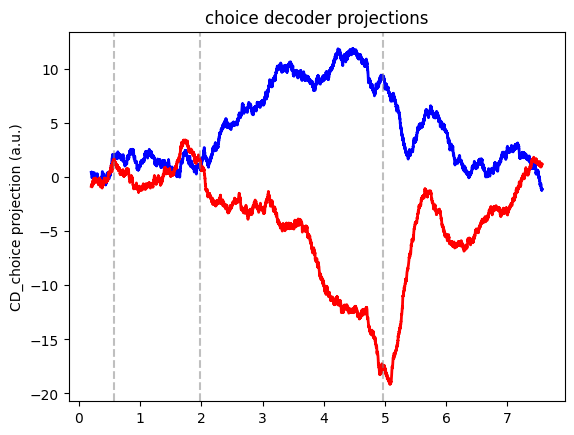

Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 206 --> 167
in house train test sorting
time taken: 12.75571346282959
calculation time: 0.15741562843322754


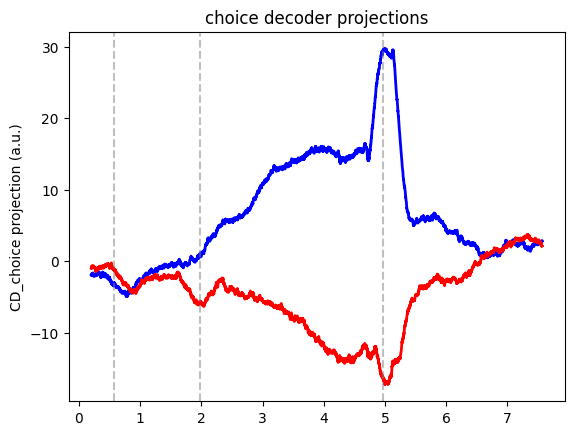

In [10]:
all_norm_right_proj = []
all_norm_left_proj = []
for path in cat(trained_paths):
    s1 = Mode(path, filter_low_perf=True, proportion_train=0.6)#, timestep=1)#, passive=False)
    right_proj, left_proj = s1.plot_CD(mode_input='choice', return_traces=True)

    overall_mean, overall_std = np.mean((right_proj, left_proj)), np.std((right_proj, left_proj))
    right_proj = (right_proj - overall_mean) / overall_std
    left_proj = (left_proj - overall_mean) / overall_std
    all_norm_right_proj.append(right_proj)
    all_norm_left_proj.append(left_proj)



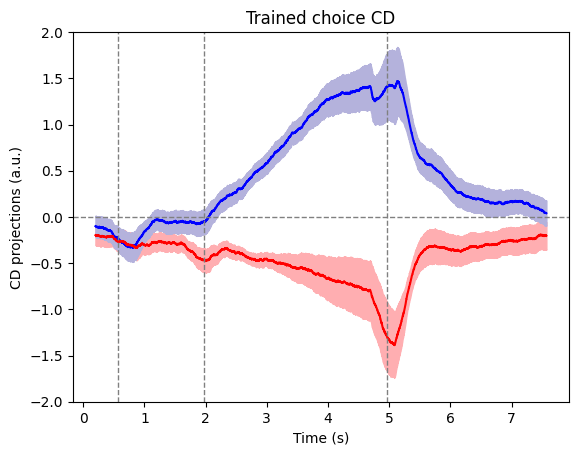

In [12]:
x=s1.t
all_std_right = np.std(all_norm_right_proj, axis=0)[:,0] / np.sqrt(len(all_norm_right_proj))
all_std_left = np.std(all_norm_left_proj, axis=0)[:,0] / np.sqrt(len(all_norm_left_proj))

f=plt.figure()
plt.plot(x,np.mean(all_norm_right_proj, axis=0)[:,0], 'b')
plt.plot(x,np.mean(all_norm_left_proj, axis=0)[:,0], 'r')

plt.fill_between(x, np.mean(all_norm_left_proj, axis=0)[:,0] - all_std_left, 
        np.mean(all_norm_left_proj, axis=0)[:,0] + all_std_left,
        color=['#ffaeb1'])
plt.fill_between(x, np.mean(all_norm_right_proj, axis=0)[:,0] - all_std_right, 
        np.mean(all_norm_right_proj, axis=0)[:,0] + all_std_right,
        color=['#b4b2dc'])


plt.axhline(0, color='gray', linewidth=1, ls='--')
plt.axvline(s1.sample, color='gray', linewidth=1, ls='--')
plt.axvline(s1.delay, color='gray', linewidth=1, ls='--')
plt.axvline(s1.response, color='gray', linewidth=1, ls='--')
plt.xlabel('Time (s)')
plt.ylabel('CD projections (a.u.)')
plt.title('Trained choice CD')
plt.ylim(-2, 2)
plt.show()